In [1]:
import re
import unicodedata
from pathlib import Path
from collections import defaultdict, Counter
from nltk.tokenize import word_tokenize
import pandas as pd
import numpy as np
import rasterio
import zipfile
import io
import json
import matplotlib.pyplot as plt
import sys
import glob

IN_FILE  = Path("datasets/resultset.xlsx")
OUT_FILE = Path("datasets/fineli_head_medians.xlsx")
HEAD_FINELLI_NO_LEMMATIZATION = Path("datasets/fineli_head_medians_no_lemmatization.xlsx")
NUMBERS_FILE = Path("datasets/fineli_pre_processed.xlsx")

# Note: zip files are not in git, download them independently and add them to the directory manually
# Source for this zip: https://drive.google.com/file/d/1Dmnco2Bmm--AGRcdxlFaOXOF3K1d2PzK/view?usp=sharing
SUOMI24_CORPUS_01_06_ZIP_PATH = Path("corpus_files/Parsed_data_1_6.zip")
BATCH_SIZE = 500

LESS_THAN_REPLACEMENT_VALUE = 0.05  # "<0.1" is treated as 0.05

In [2]:
def to_number(value):
    """'12.5' -> 12.5, '<0.1' -> 0.05, 'N/A' or empty -> NaN"""
    if pd.isna(value):
        return np.nan
    value = str(value).strip().replace(',', '.')  # In case '12,5' -> '12.5'
    if value.upper() in {'N/A', 'NA', '-', ''}:
        return np.nan
    if value.startswith('<'):  # '<0.1' -> '0.05'
        return LESS_THAN_REPLACEMENT_VALUE
    try:
        return float(value)
    except ValueError:
        return np.nan


def head_term(name):
    """'Ahven, paistettu voissa' -> 'ahven'"""
    head = str(name).split(',')[0]  # text before the first comma
    head = head.split('/')[0]  # first alternative only, 'Aromisuola/yrttisuola 71 %' -> 'aromisuola'
    head = re.split(r'\d', head)[0]  # cut at the first number, 'kasvirasvalevite 70 %' -> 'kasvirasvalevite'
    head = unicodedata.normalize('NFC', head)  # consistent å/ä/ö for later matching
    head = re.sub(r'\s+', ' ', head).strip().lower()  # replace multiple whitespaces with single whitespaceS
    return head

In [3]:
from simplemma import Lemmatizer
from simplemma.strategies import DictionaryLookupStrategy
from simplemma.strategies.dictionaries import DefaultDictionaryFactory

lemmatizer = Lemmatizer(
    lemmatization_strategy=DictionaryLookupStrategy(dictionary_factory=DefaultDictionaryFactory())
)


KEEP_AS_IS = {'tee', 'voi'}   # already the right lemma, but the lemmatizer reads them as verbs

def lemmatize_word(word):
    """'ahvenet' -> 'ahven', 'tee' -> 'tee' (not changed: no inflection ending)"""
    if not word or word in KEEP_AS_IS:
        return word
    return lemmatizer.lemmatize(word, lang='fi').lower()


def lemmatize_term(term):
    """'ahvenet foliossa' -> 'ahven folio', 'ateria-ainekset' -> 'ateria-aines'"""
    return ' '.join('-'.join(lemmatize_word(part) for part in word.split('-'))
                    for word in term.split(' '))

# print(lemmatize_term('ahvenet foliossa'))  # expect: ahven folio
# print(lemmatize_term('herneet'))  # expect: herne
# print(lemmatize_term('ateria-ainekset'))  # check how the hyphen is handled (expect: ateria-aines)
# print(lemmatize_term('tee'))  # expect: tee
# print(lemmatize_term('voi'))  # expect: voi

In [4]:
def read_fineli_raw(in_file):
    return pd.read_excel(in_file, dtype=str)

def convert_to_numbers(raw):
    nutrient_cols = [c for c in raw.columns if c not in ('id', 'name')]
    numbers = raw.copy()
    numbers[nutrient_cols] = raw[nutrient_cols].apply(lambda col: col.map(to_number))
    return numbers

def calculate_medians(numbers):
    df = numbers.drop(columns='id')
    df['name'] = df['name'].map(head_term)
    df = df[df['name'] != '']

    lemma_map = {head: lemmatize_term(head) for head in df['name'].unique()}
    df['name'] = df['name'].map(lemma_map)

    return df.groupby('name').median()

def calculate_medians_no_lemmatization(numbers):
    df = numbers.drop(columns='id')
    df['name'] = df['name'].map(head_term)
    return df.groupby('name').median()

def load_fineli_dataset(in_file=IN_FILE, numbers_file=NUMBERS_FILE, out_file=OUT_FILE):
    raw = read_fineli_raw(in_file)

    numbers = convert_to_numbers(raw)
    # numbers.to_excel(numbers_file, index=False)

    medians = calculate_medians(numbers)
    medians.to_excel(out_file)
    return medians

def load_fineli_medians(out_file=OUT_FILE):
    return pd.read_excel(out_file, index_col=0)

In [5]:
# fineli = load_fineli_dataset()  # creates new finelli_head_medians.xlsx
fineli = load_fineli_medians()
# print("\n", fineli)


fineli_lemmas = set(fineli.index)
fineli_dict = fineli.fillna(0)[~fineli.index.duplicated(keep='first')].to_dict('index')

In [6]:
import gzip, io, json, os, zipfile
from collections import Counter
from pathlib import Path

fineli_lemmas = set(fineli.index)
fineli_dict = (fineli.fillna(0)[~fineli.index.duplicated(keep='first')]
                     .to_dict('index'))

# For multi-word foods such as "ahven folio" (longest match wins)
MAX_NGRAM = max(len(f.split(' ')) for f in fineli_lemmas)
FIRST_WORDS = {f.split(' ')[0] for f in fineli_lemmas}

OUT_DIR = Path("datasets/parsed")
OUT_DIR.mkdir(parents=True, exist_ok=True)


def find_foods(lemmas):
    """lemmas: list of lowercase str -> Counter({food: n_occurrences})"""
    found, i, n = Counter(), 0, len(lemmas)
    while i < n:
        if lemmas[i] in FIRST_WORDS:
            for k in range(min(MAX_NGRAM, n - i), 0, -1):
                cand = ' '.join(lemmas[i:i + k])
                if cand in fineli_lemmas:
                    found[cand] += 1
                    i += k
                    break
            else:
                i += 1
        else:
            i += 1
    return found


def lower_list(xs):
    return [str(w).lower() for w in (xs or [])]


def make_message(idx, date, raw_tokens, lemmas, foods):
    return {
        "idx": idx,  # 0 = thread start, 1...n = comments
        "date": date,
        "text": ' '.join(map(str, raw_tokens or [])),
        "lemmas": ' '.join(lemmas),
        "foods": dict(foods),
    }


def process_thread(d, out_f, stats):
    date = str(d.get("date") or "")
    month = date[:7]
    if len(month) != 7:
        return

    title = d.get("title") or ""
    title_lem = lower_list(d.get("orig_msg_lemmatized"))
    comments = d.get("comments") or []

    # Monthly totals over all threads
    # (could probably be removed but decided to add to see better if the script works)
    s = stats.setdefault(month, Counter())
    s["threads"] += 1
    s["comments"] += len(comments)
    s["tokens"] += len(title_lem)

    title_foods = find_foods(title_lem)
    thread_foods = Counter(title_foods)
    messages = []
    if title_foods:
        messages.append(make_message(0, date, d.get("orig_msg"), title_lem, title_foods))

    for i, c in enumerate(comments, start=1):
        c_lem = lower_list(c.get("orig_msg_lemmatized"))
        s["tokens"] += len(c_lem)
        f = find_foods(c_lem)
        if f:
            thread_foods.update(f)
            messages.append(make_message(i, c.get("date") or date,
                                         c.get("orig_msg"), c_lem, f))

    if not thread_foods:
        return
    s["matched_threads"] += 1

    out_f.write(json.dumps({
        "thread_id": d.get("thread_id"),
        "topic": d.get("topic_names"),
        "date": date,
        "month": month,
        "title": title,
        "title_lemmas": ' '.join(title_lem),
        "title_n_tokens": len(title_lem),
        "title_n_chars": len(title),
        "n_comments": len(comments),
        "foods": dict(thread_foods),  # total mentions, title + comments
        "foods_in_title": sorted(title_foods),
        "messages": messages,
    }, ensure_ascii=False) + "\n")


def parse_zip(zip_path):
    zip_path = Path(zip_path)
    with zipfile.ZipFile(zip_path) as z:
        files = [f for f in z.namelist() if f.endswith("with_comments.txt")]
        for file_name in files:
            tag = file_name.split('/')[-2]
            out_path = OUT_DIR / f"{zip_path.stem}_{tag}.jsonl.gz"
            stats_path = OUT_DIR / f"{zip_path.stem}_{tag}_stats.json"
            if out_path.exists() and stats_path.exists():
                print(f"Skipping {file_name} (already parsed)")
                continue

            print(f"Processing {file_name}")
            tmp = Path(str(out_path) + ".tmp")
            stats = {}
            with z.open(file_name) as raw, io.TextIOWrapper(raw, encoding="utf-8") as text, \
                 gzip.open(tmp, "wt", encoding="utf-8") as out_f:
                for n, line in enumerate(text):
                    line = line.strip()
                    if not line:
                        continue
                    try:
                        d = json.loads(line)
                    except json.JSONDecodeError:
                        continue
                    if n == 0:
                        print("  keys:", list(d.keys()))
                        print("  title:", d.get("title"), "| orig_msg:", d.get("orig_msg"))
                    process_thread(d, out_f, stats)

            os.replace(tmp, out_path)   # file only appears once it is complete
            with open(stats_path, "w", encoding="utf-8") as f:
                json.dump({m: dict(c) for m, c in stats.items()}, f)


In [7]:
# parse_zip(SUOMI24_CORPUS_01_06_ZIP_PATH)

In [8]:
def load_monthly_counts():
    """month x food table of mention counts, read from the parsed files."""
    rows = []
    for p in glob.glob(str(OUT_DIR / "*.jsonl.gz")):
        with gzip.open(p, "rt", encoding="utf-8") as f:
            for line in f:
                r = json.loads(line)
                for food, n in r["foods"].items():
                    rows.append((r["month"], food, n))
    return (pd.DataFrame(rows, columns=["month", "food", "n"])
              .groupby(["month", "food"])["n"].sum().unstack(fill_value=0))


counts = load_monthly_counts()
# print(counts.head(1))

food_nutrients = pd.DataFrame.from_dict(fineli_dict, orient='index')
# for each month sum of nutrients (times the food was mentioned * nutrition per food)
monthly_nutrition_df = counts.dot(food_nutrients.loc[counts.columns])

# print("Total counts of top 10 foods:")
# print(counts.sum().nlargest(10))

In [9]:
# print(monthly_nutrition_df.head(2))

In [10]:
def draw_monthly_nutrition_intake(monthly_df):
    """
    Draw monthly intake evolution of nutrients.
    monthly_df: DataFrame, index = 'YYYY-MM', columns = nutrient names.
    """
    final_results_df = monthly_df.copy()
    final_results_df.index.name = 'Month'
    final_results_df = final_results_df.sort_index()
    final_results_df.index = final_results_df.index.astype(str)

    nutrient_groups = {
        "Energy (kJ)": [
            'energia, laskennallinen (kJ)'
        ],
        "Main Macros (g)": [
            'proteiini (g)', 'hiilihydraatti imeytyvä (g)', 'rasva (g)', 'alkoholi (g)'
        ],
        "Carbs, Sugars & Fibers (g)": [
            'sokerit (g)', 'fruktoosi (g)', 'galaktoosi (g)', 'glukoosi (g)',
            'laktoosi (g)', 'maltoosi (g)', 'sakkaroosi (g)', 'tärkkelys (g)',
            'kuitu, kokonais- (g)', 'kuitu veteen liukenematon (g)',
            'polysakkaridi, vesiliukoinen ei-selluloosa (g)', 'sokerialkoholi (g)'
        ],
        "Fatty Acids (g)": [
            'rasvahapot yhteensä (g)', 'rasvahapot monityydyttymättömät (g)',
            'rasvahapot yksittäistyydyttymättömät cis (g)', 'rasvahapot tyydyttyneet (g)',
            'rasvahapot trans (g)', 'rasvahapot n-3 monityydyttymättömät (g)',
            'rasvahapot n-6 monityydyttymättömät (g)', 'orgaaniset hapot (g)', 'tryptofaani (mg)'
        ],
        "Specific Fats & Cholesterol (mg)": [
            'rasvahappo 18:2 cis,cis n-6 (linolihappo) (mg)',
            'rasvahappo 18:3 n-3 (alfalinoleenihappo) (mg)',
            'rasvahappo 20:5 n-3 (EPA) (mg)', 'rasvahappo 22:6 n-3 (DHA) (mg)',
            'kolesteroli (GC) (mg)', 'sterolit (mg)'
        ],
        "Minerals & Salts (mg)": [
            'kalsium (mg)', 'rauta (mg)', 'kalium (mg)', 'magnesium (mg)',
            'natrium (mg)', 'suola (mg)', 'fosfori (mg)', 'sinkki (mg)'
        ],
        "Minerals & Salts (µg)": [
            'jodidi (jodi) (µg)', 'seleeni (µg)',
        ],
        "Vitamins (mg)": [
            'C-vitamiini (mg)', 'E-vitamiini alfatokoferoli (mg)',
            'niasiiniekvivalentti NE (mg)',
            'niasiini (nikotiinihappo + nikotiiniamidi) (mg)',
            'pyridoksiini vitameerit (vetykloridi) (B6) (mg)',
            'riboflaviini (B2) (mg)', 'tiamiini (B1) (mg)'
        ],
        "Vitamins (µg)": [
            'A-vitamiini RAE (µg)', 'B12-vitamiini (kobalamiini) (µg)',
            'D-vitamiini (µg)', 'K-vitamiini (µg)', 'folaatti, kokonais- (µg)',
            'karotenoidit (µg)'
        ]
    }

    for group_name, columns in nutrient_groups.items():
        valid_cols = [col for col in columns if col in final_results_df.columns]

        if not valid_cols:
            print(f"Skipping {group_name} because none of those columns exist in the dataframe.")
            continue

        plt.figure(figsize=(21, 7))

        for col in valid_cols:
            plt.plot(final_results_df.index, final_results_df[col], marker='o', label=col)

        plt.title(f"Monthly Evolution: {group_name}", fontsize=16, fontweight='bold')
        plt.xlabel("Month", fontsize=12)
        plt.ylabel("Total nutrition (100g per mention)", fontsize=12)
        tick_positions = list(range(0, len(final_results_df.index), 6))
        # Ensure the last month is always shown
        last_position = len(final_results_df.index) - 1
        if last_position not in tick_positions:
            tick_positions.append(last_position)
        plt.xticks(
            ticks=tick_positions,
            labels=final_results_df.index[tick_positions],
            rotation=45,
            ha='right'
        )
        plt.plot([], [], ' ', label="Each time a food is mentioned,\nthe total amount is appended\nby the nutrient amount in\n100 grams of the food")
        plt.legend(loc='upper left', bbox_to_anchor=(1, 1), borderaxespad=0.)

        plt.grid(True, linestyle='--', alpha=0.6)

        plt.tight_layout()
        plt.show()

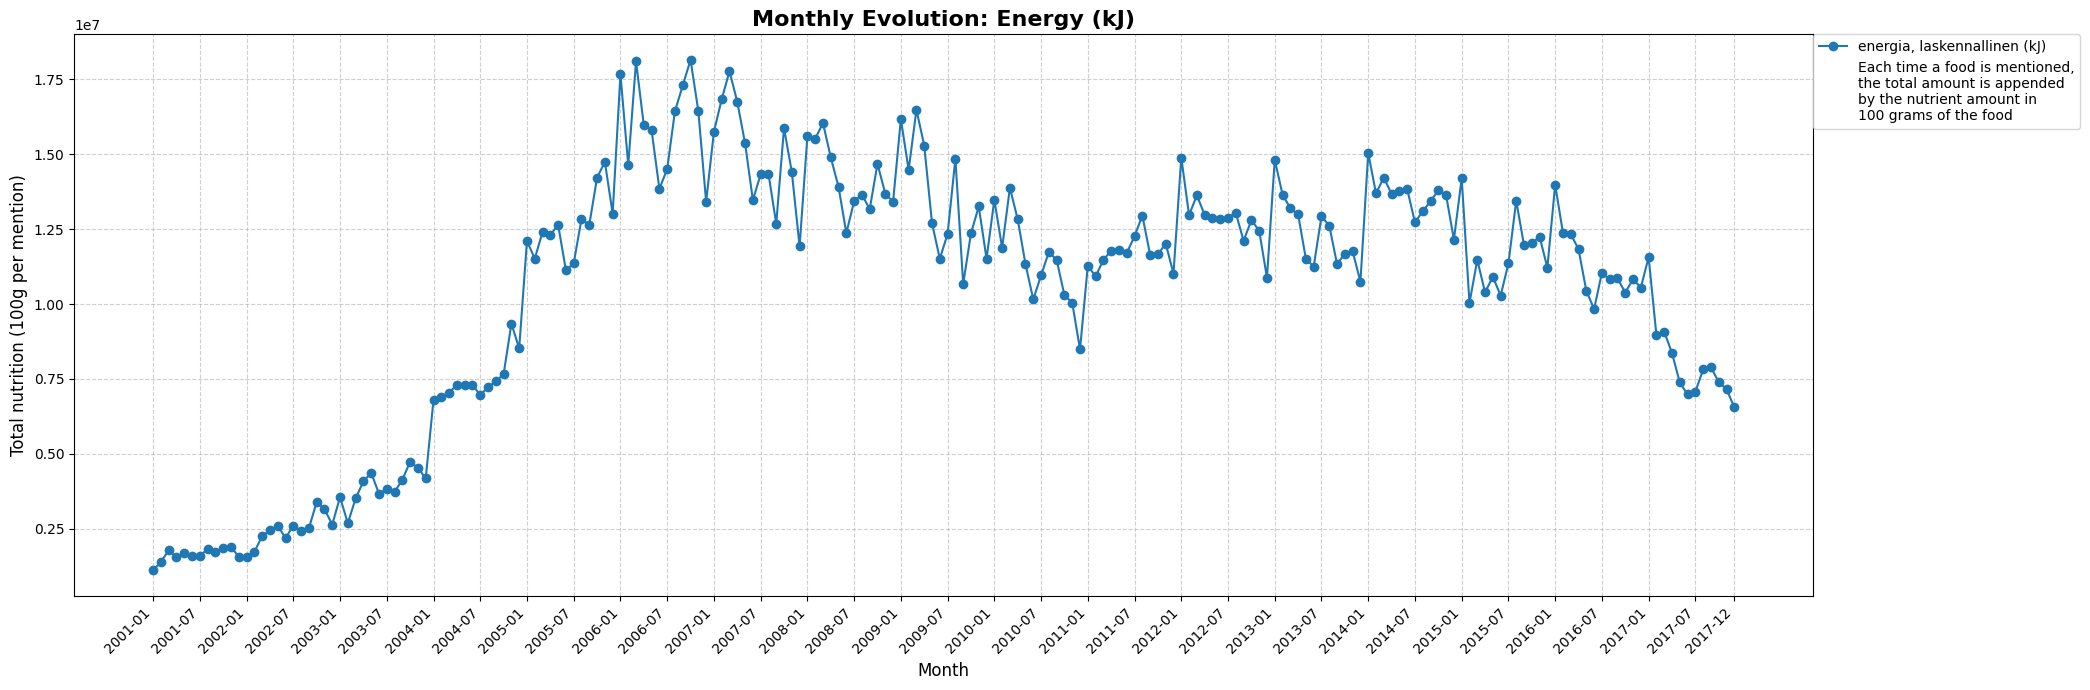

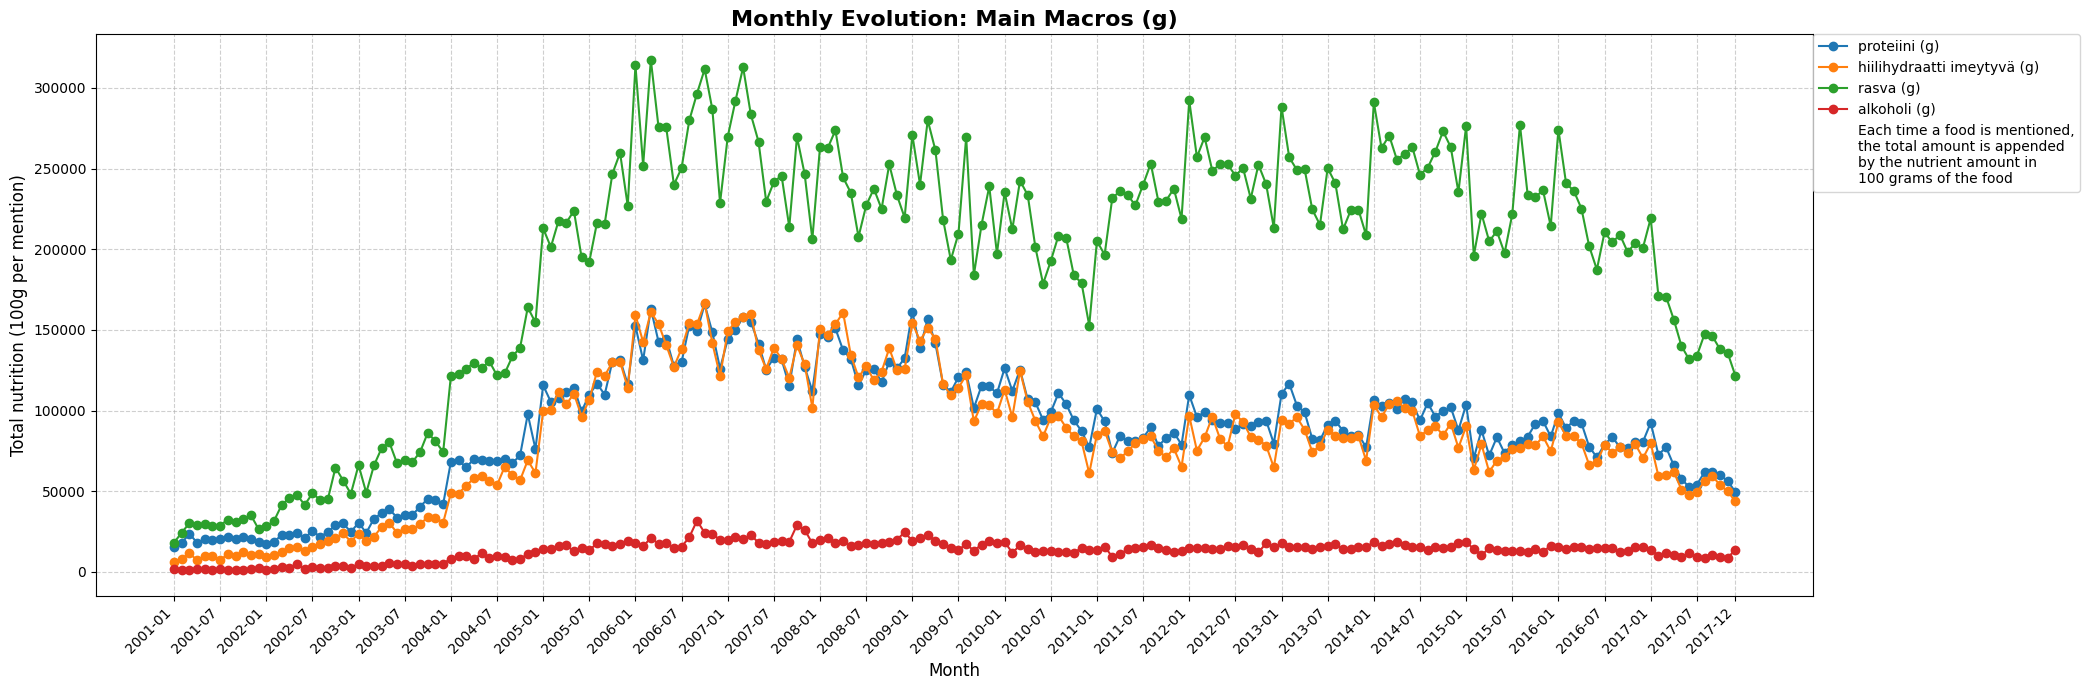

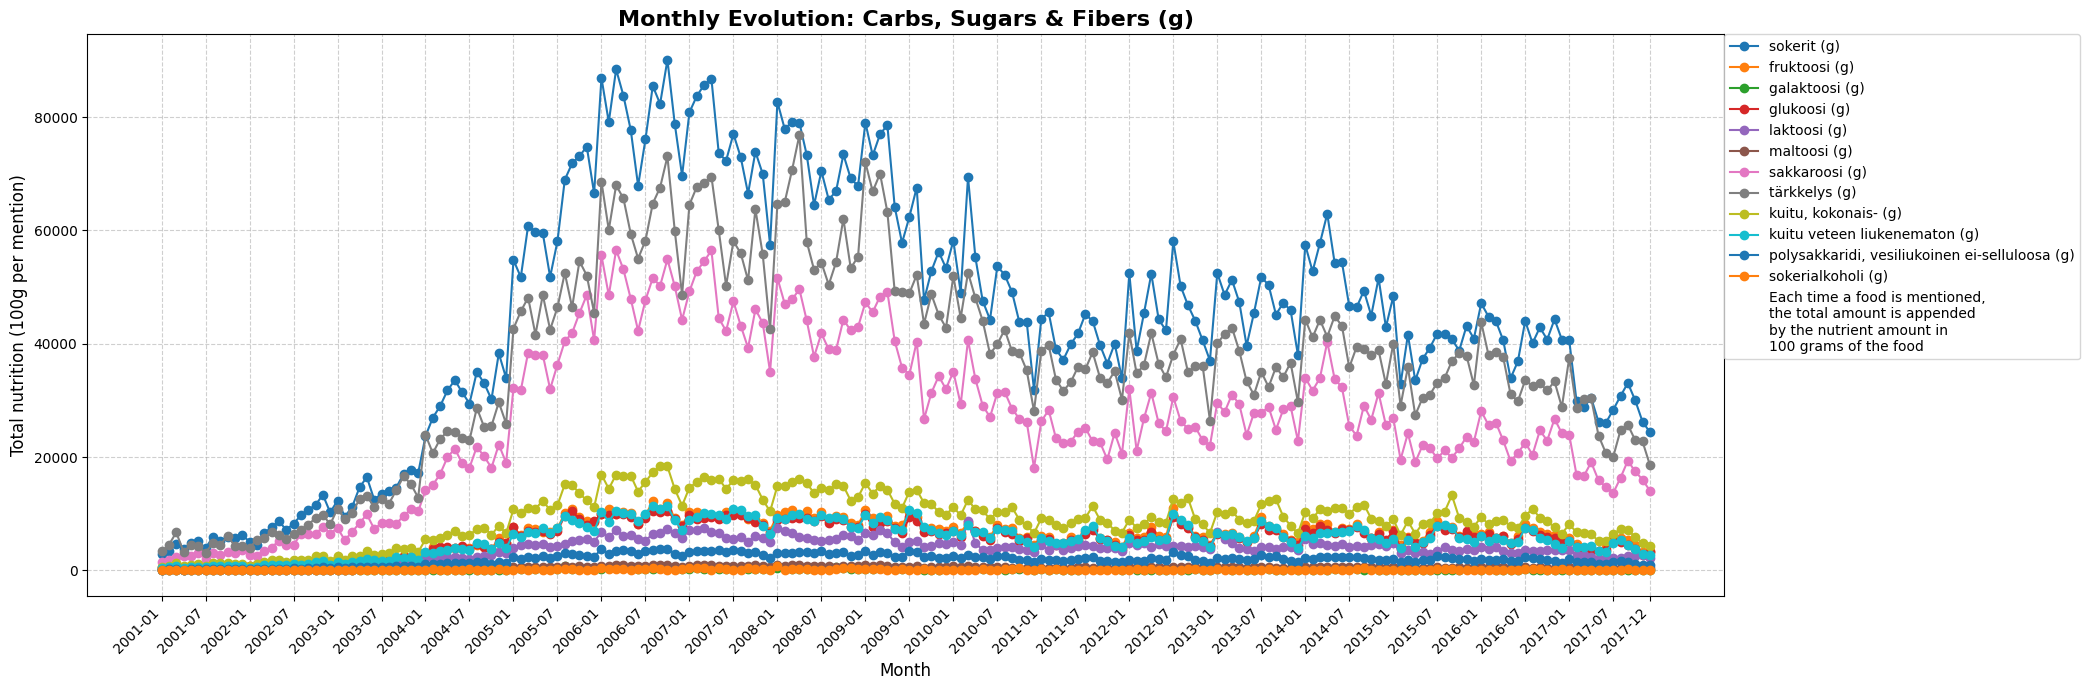

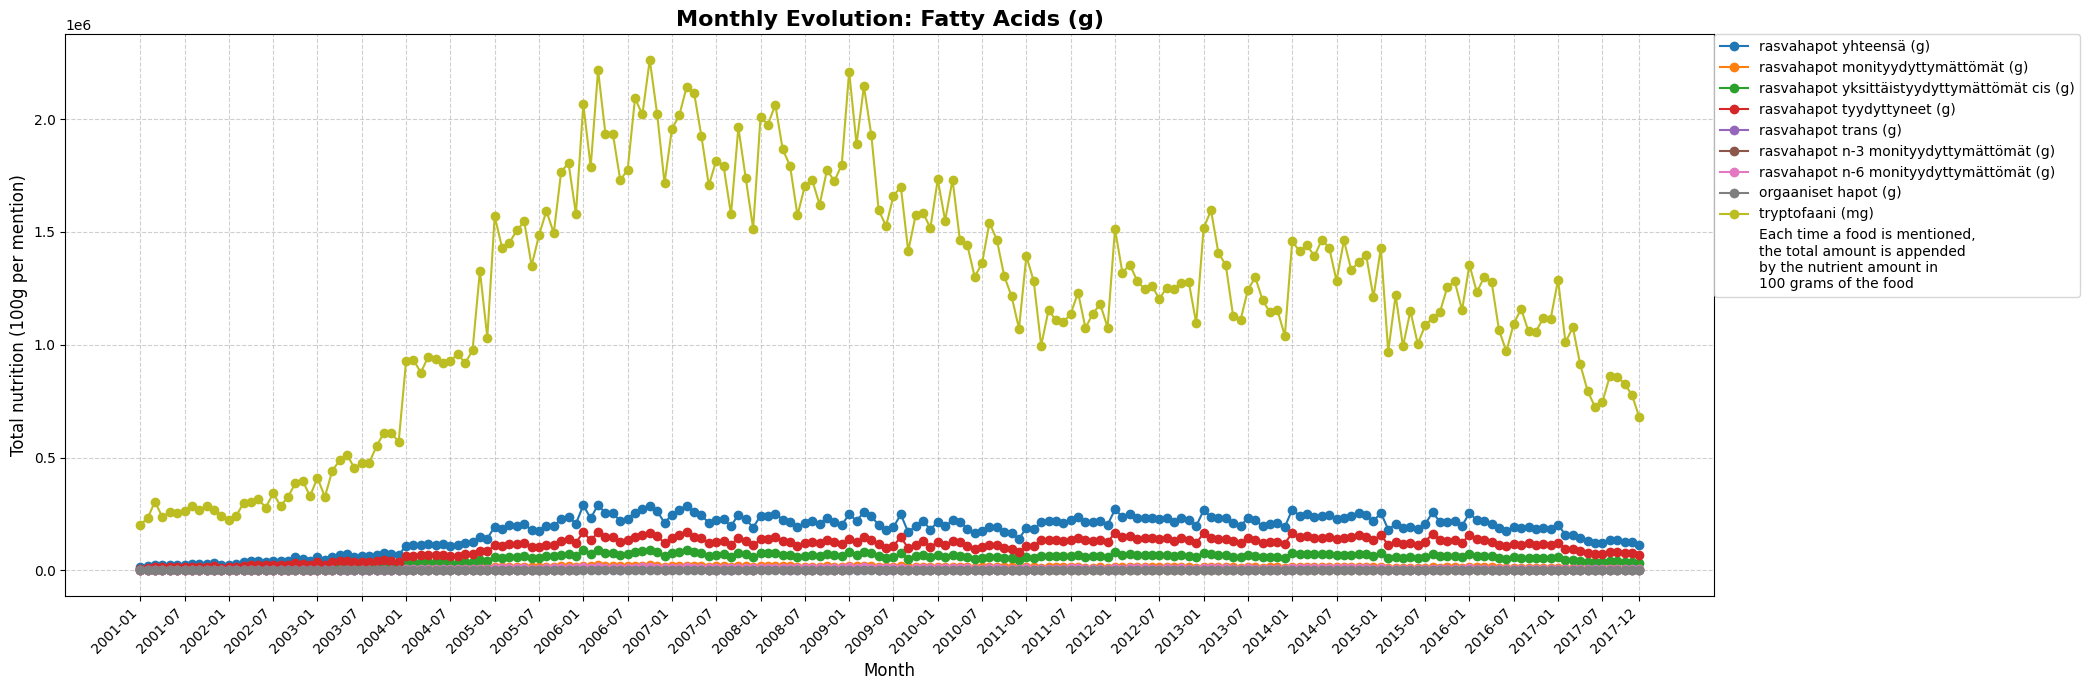

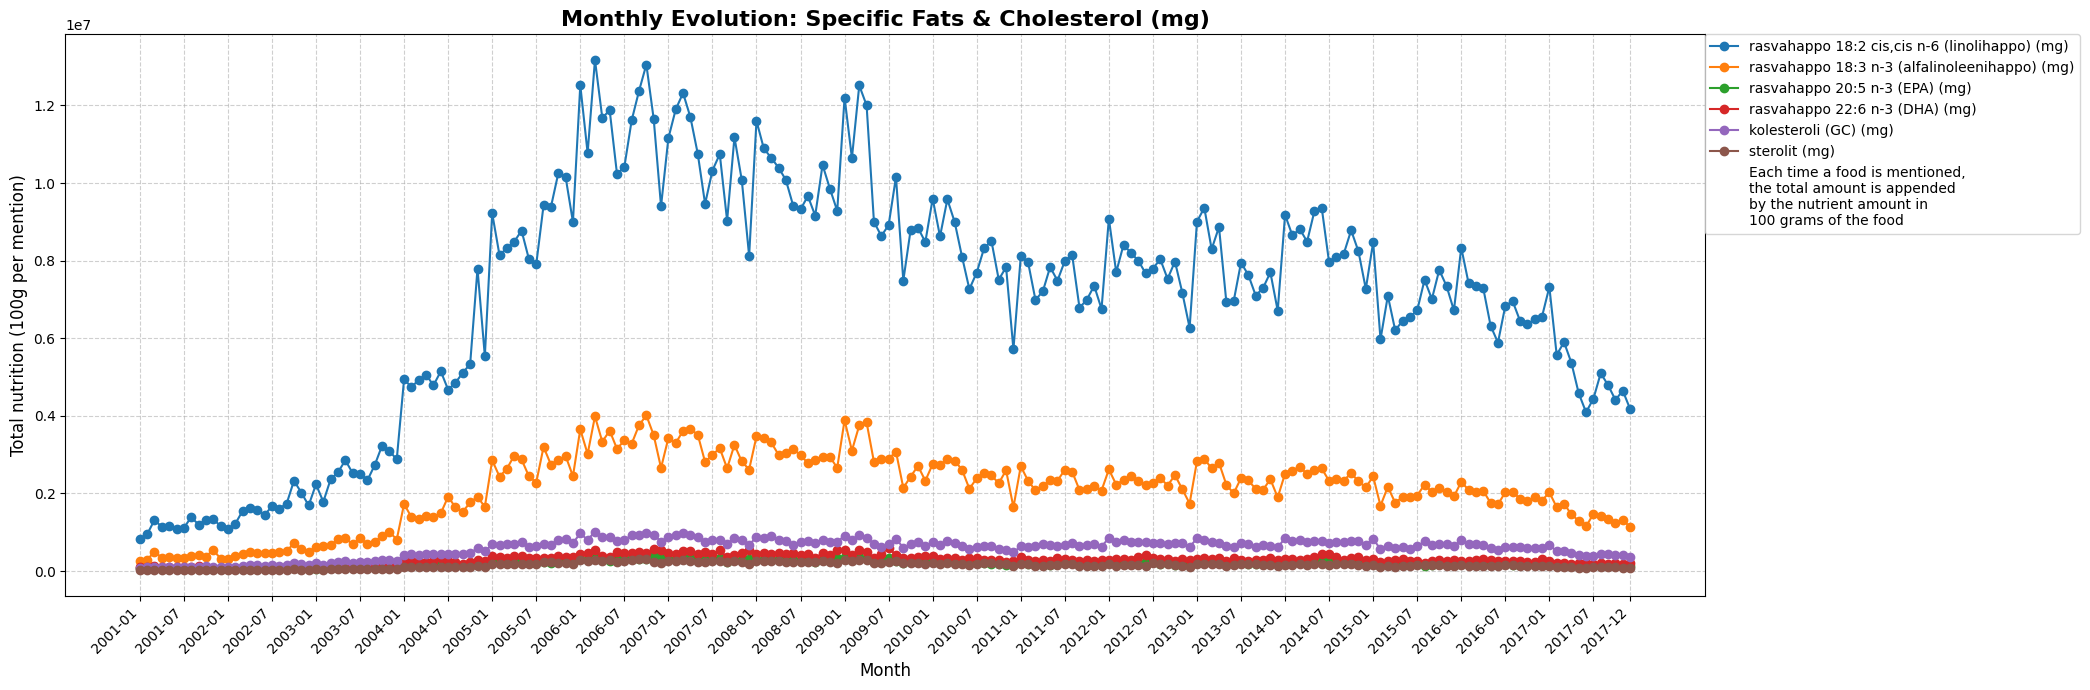

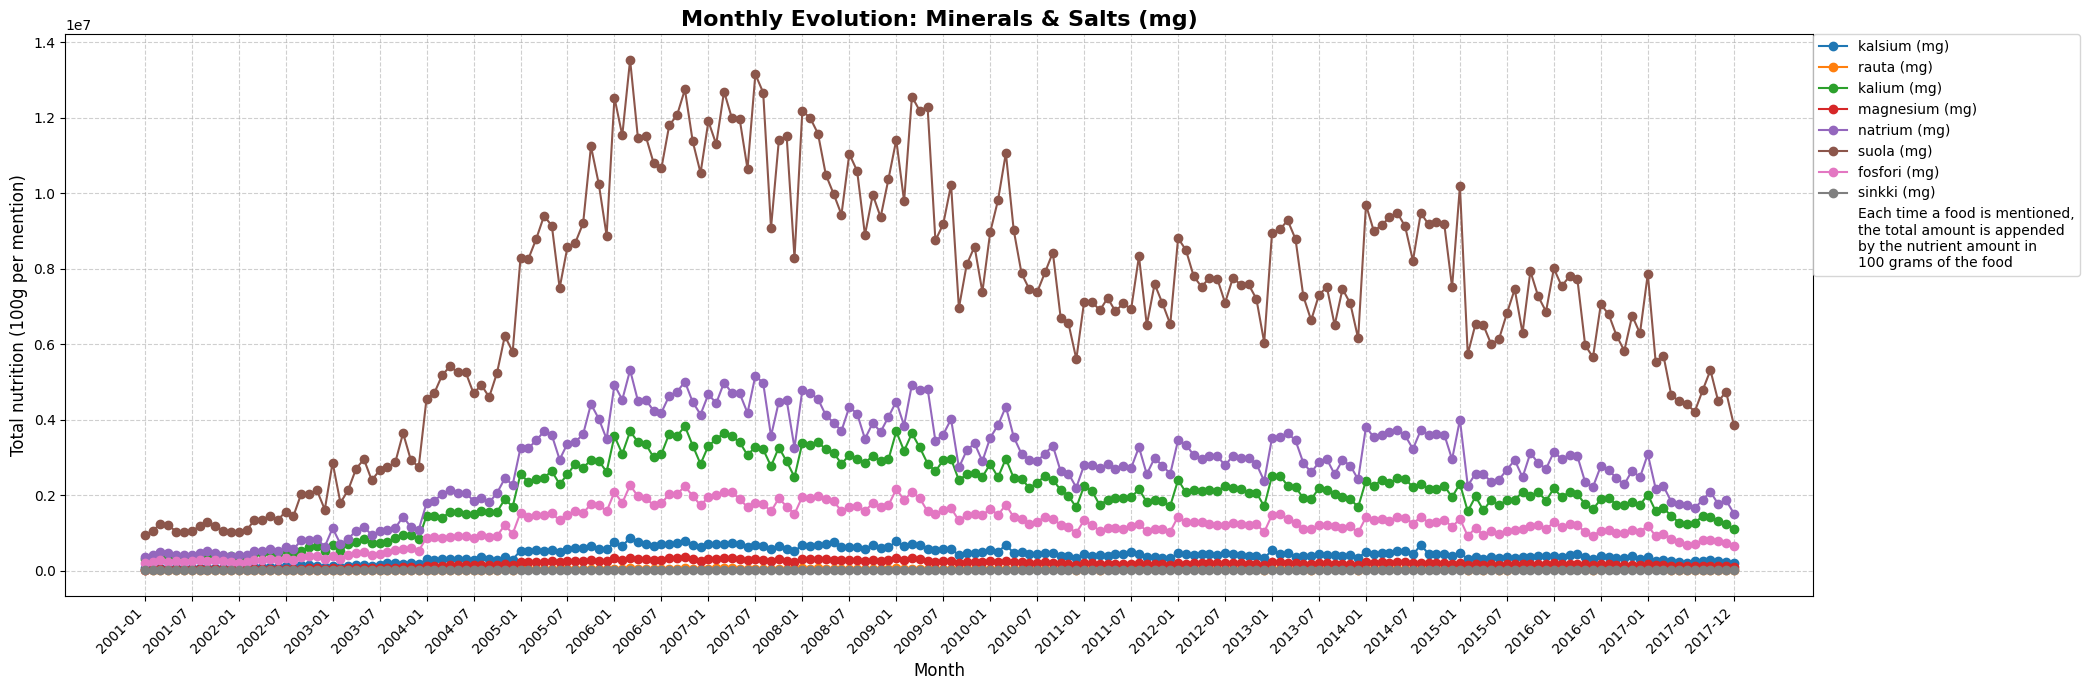

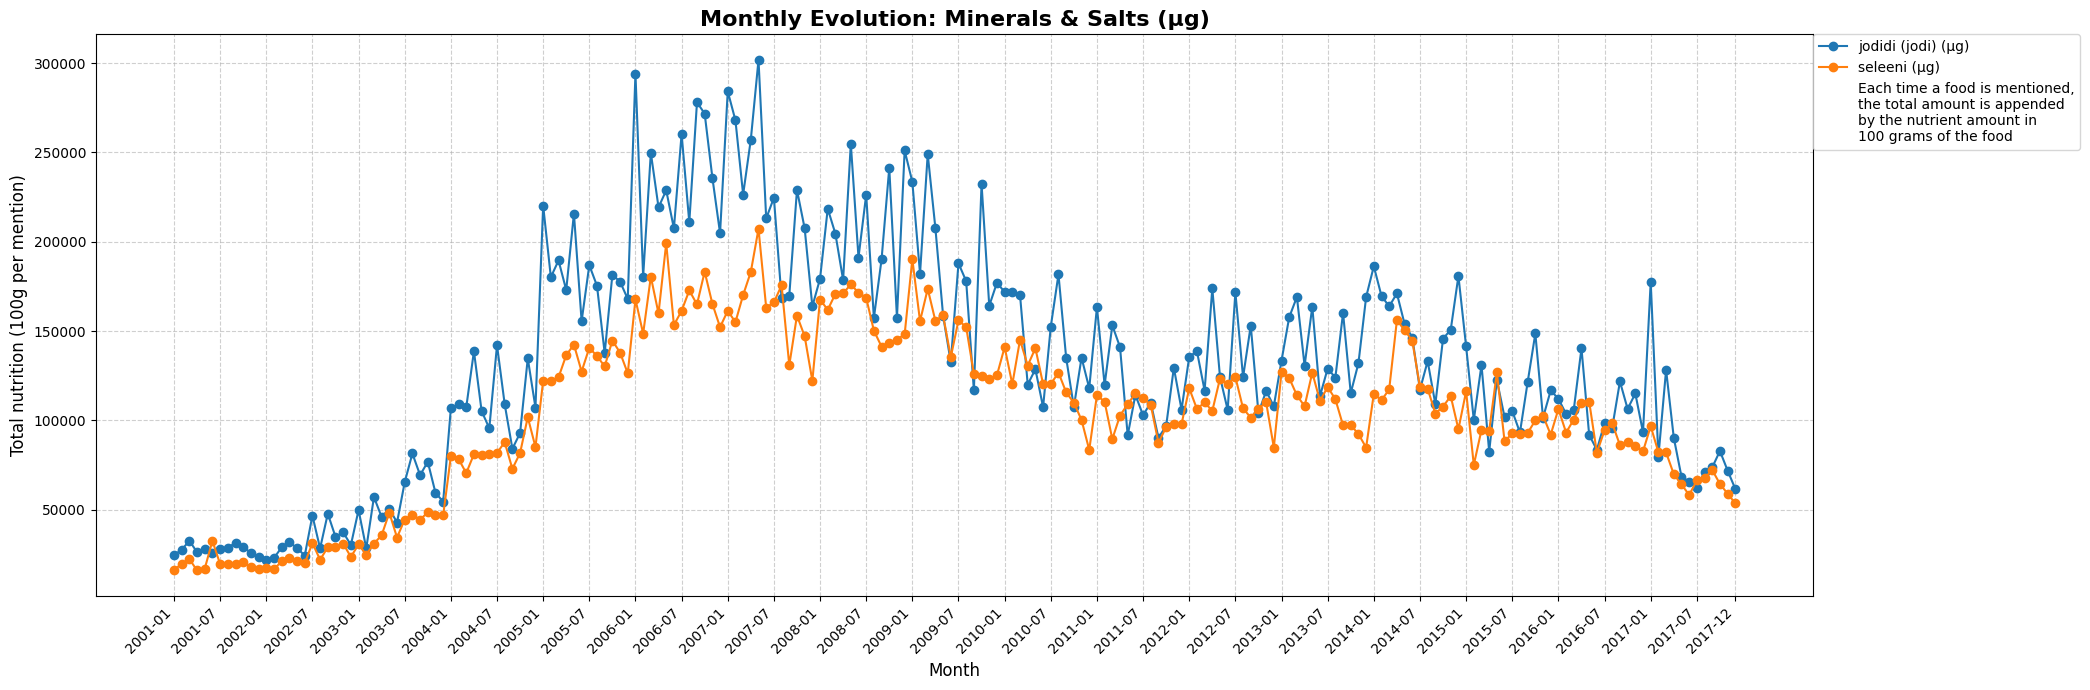

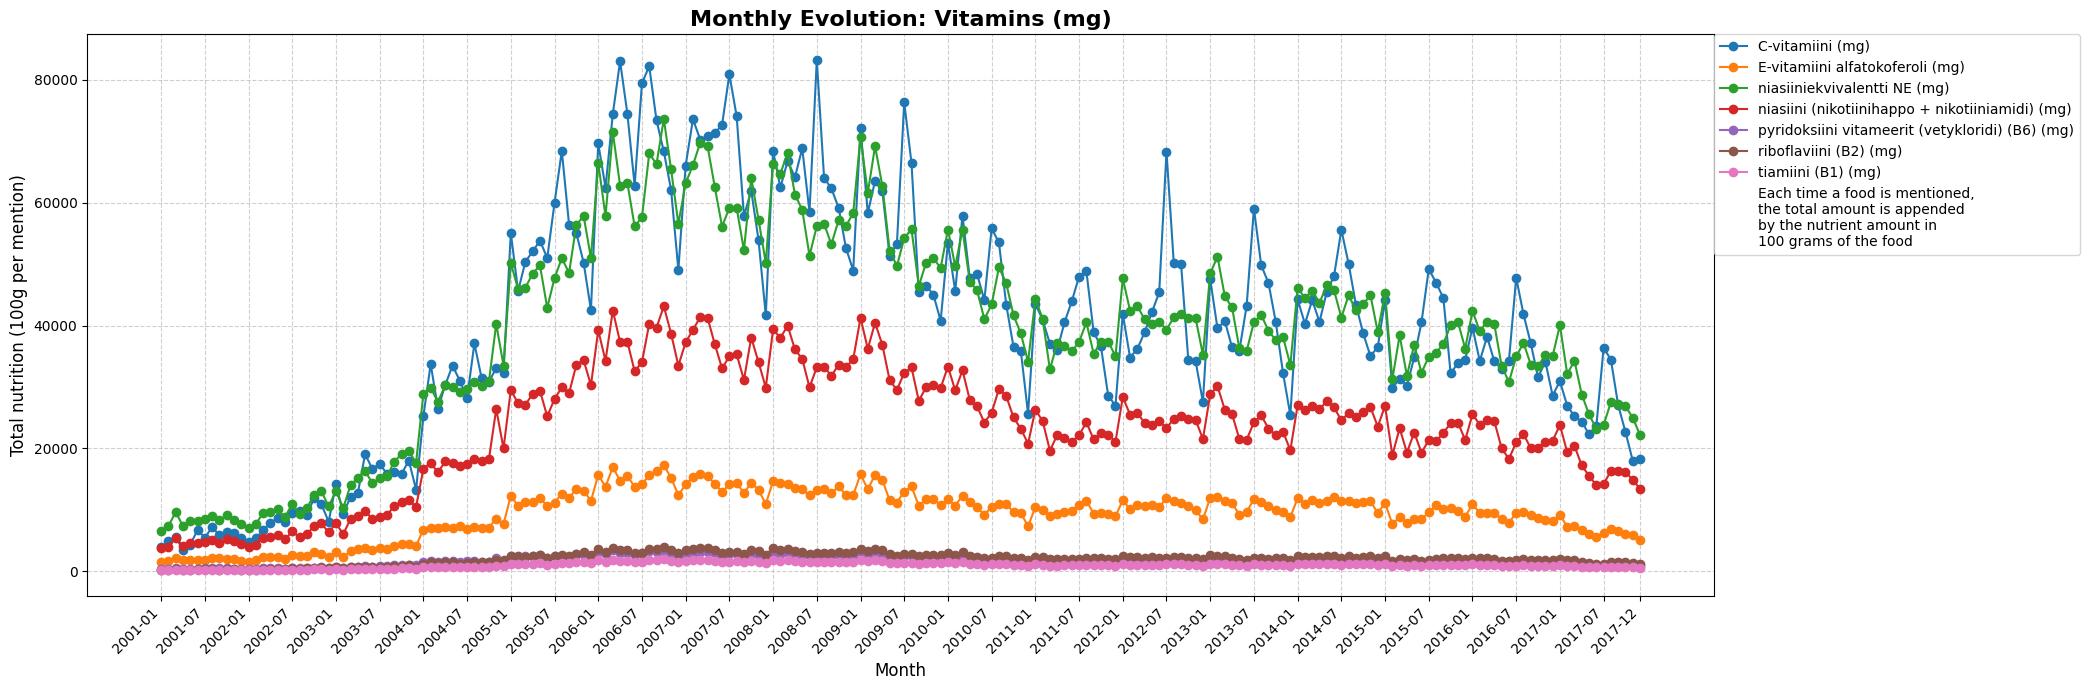

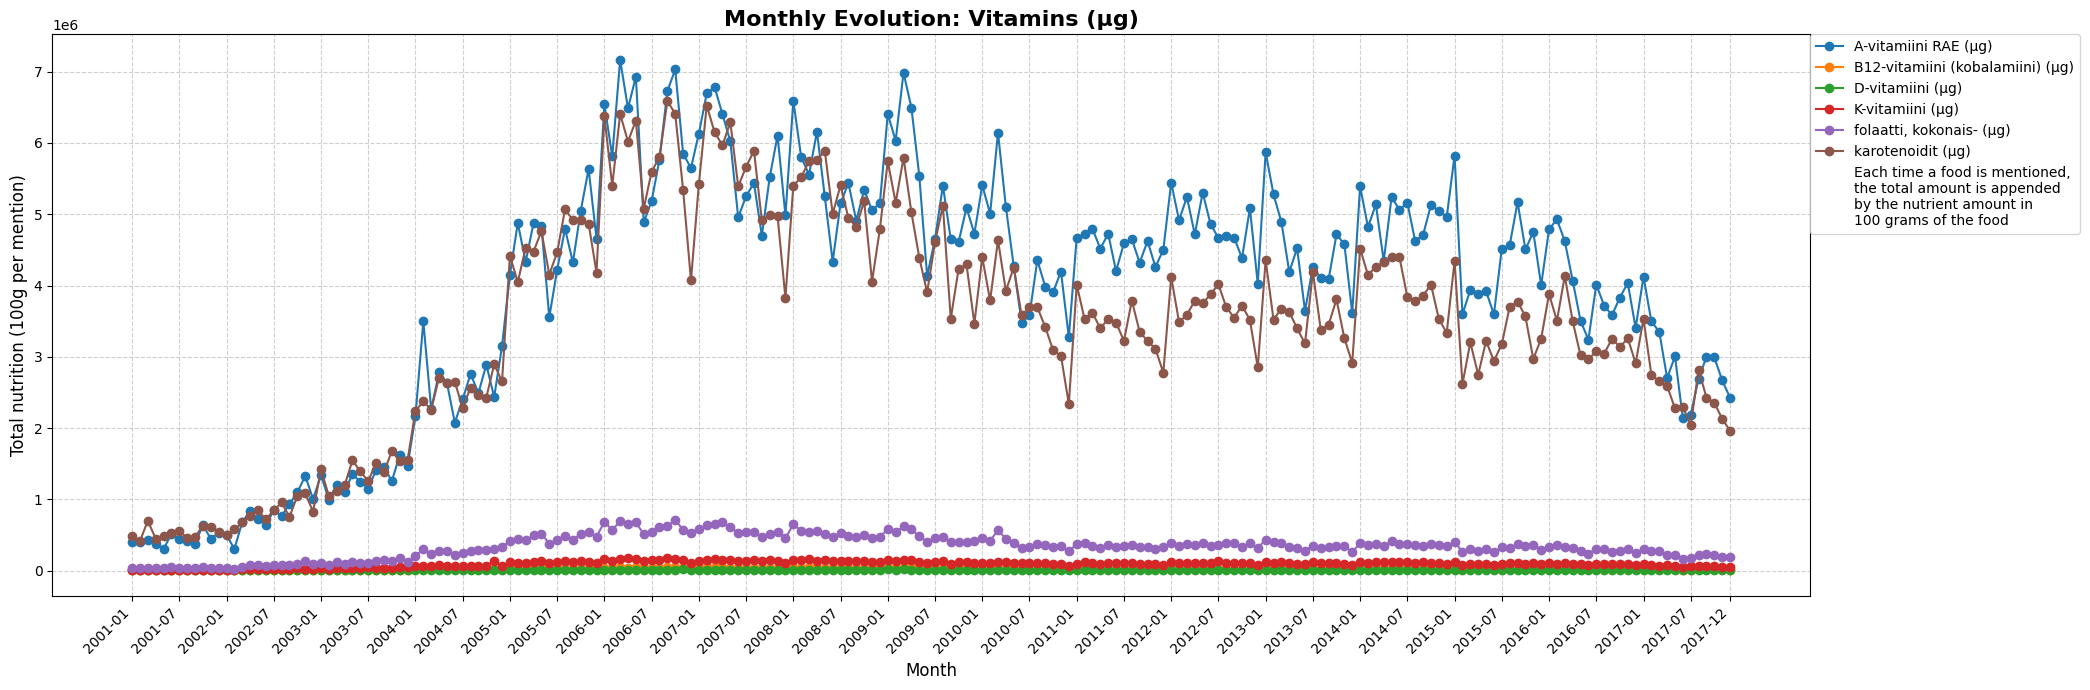

In [11]:
# Part 1) results

draw_monthly_nutrition_intake(monthly_nutrition_df)

In [12]:
# NOTE: Just some helpful prints for testing

# Look at one saved record
first_file = sorted(glob.glob(str(OUT_DIR / "*.jsonl.gz")))[0]
with gzip.open(first_file, "rt", encoding="utf-8") as f:
    first = None
    for line in f:
        first = json.loads(line)
        break

# print(json.dumps(first, ensure_ascii=False, indent=2))

In [13]:
# NOTE: Just some helpful prints for testing

# print("\nDistinct foods found:", counts.shape[1])
# print(counts.sum().nlargest(25))

In [14]:
# NOTE: Just some helpful prints for testing

def show_fields():
    p = sorted(glob.glob(str(OUT_DIR / "*.jsonl.gz")))[0]

    with gzip.open(p, "rt", encoding="utf-8") as f:
        next(f)
        next(f)
        next(f)
        # 4th in this dataset is a good example
        r = json.loads(next(f))

    print(r.keys())
    return r

# show_fields()

In [15]:
# Part 2)

def load_titles():
    rows = []
    for p in sorted(glob.glob(str(OUT_DIR / "*.jsonl.gz"))):
        with gzip.open(p, "rt", encoding="utf-8") as f:
            for line in f:
                r = json.loads(line)
                rows.append((r["month"], r["date"], r["thread_id"],
                             r["title"], r["title_lemmas"], r["foods"], len(r["foods"])))
    return pd.DataFrame(rows, columns=["month", "date", "thread_id",
                                       "title", "title_lemmas", "foods", "n_foods"])


titles_df = load_titles()
# titles_df.to_csv("datasets/titles_by_month.csv.gz", index=False)
monthly_titles = {month: g for month, g in titles_df.groupby("month")}

print(len(titles_df), "titles in", len(monthly_titles), "months\n")
# print(monthly_titles[sorted(monthly_titles)[0]].head())

1237182 titles in 204 months



In [16]:
from afinn import Afinn
from scipy.stats import pearsonr

afinn = Afinn(language='fi')


def score_titles(df, column="title"):
    return pd.Series([afinn.score(t) for t in df[column]], index=df.index)


def monthly_sentiment_from_titles(titles_by_month, column="title"):
    rows = {}
    for month, df in titles_by_month.items():
        scores = score_titles(df, column)
        rows[month] = {
            "sentiment_sum": scores.sum(),
            "n_titles": len(df),
        }
    return pd.DataFrame.from_dict(rows, orient="index").sort_index()


monthly_sentiment = monthly_sentiment_from_titles(monthly_titles)


In [17]:
ENERGY_COL = 'energia, laskennallinen (kJ)'


def build_comparison(nutrition_df, sentiment_df, nutrient=ENERGY_COL):
    return sentiment_df.join(nutrition_df[[nutrient]].rename(columns={nutrient: "nutrition_sum"}),
                        how="inner")


def pearson_with_nutrition(comp, other_col):
    r, p = pearsonr(comp[other_col], comp["nutrition_sum"])
    return pd.DataFrame([{"series": other_col, "nutrition": "nutrition_sum",
                          "pearson_r": r, "p_value": p, "n_periods": len(comp)}])

comparison = build_comparison(monthly_nutrition_df, monthly_sentiment)

In [18]:
def plot_vs_nutrition(comp, other_col, other_name, other_axis_label,
                      other_color="tab:red", other_marker="s",
                      nutrition_label="Nutrition sum (energy, kJ)",
                      period_label="Monthly", x_label="Month"):
    x = pd.to_datetime(comp.index)
    r, p = pearsonr(comp[other_col], comp["nutrition_sum"])

    fig, ax1 = plt.subplots(figsize=(21, 7))

    ax1.plot(x, comp["nutrition_sum"], color="tab:green", marker="o", label=nutrition_label)
    ax1.set_xlabel(x_label)
    ax1.set_ylabel(nutrition_label, color="tab:green")
    ax1.tick_params(axis="y", labelcolor="tab:green")
    ax1.grid(True, linestyle="--", alpha=0.6)

    ax2 = ax1.twinx()
    ax2.plot(x, comp[other_col], color=other_color, marker=other_marker, label=other_axis_label)
    ax2.set_ylabel(other_axis_label, color=other_color)
    ax2.tick_params(axis="y", labelcolor=other_color)

    lines = ax1.get_lines() + ax2.get_lines()
    ax1.legend(lines, [l.get_label() for l in lines], loc="upper left")

    plt.title(f"{period_label} {other_name} vs. nutrition (Pearson r = {r:.3f}, p = {p:.3g})",
              fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()

         sentiment_sum  n_titles  nutrition_sum
2001-01           -9.0       775   1.106156e+06
2001-02          -43.0       948   1.393052e+06
2001-03           22.0      1063   1.774585e+06
2001-04            1.0       957   1.560076e+06
2001-05           38.0      1056   1.673610e+06
...                ...       ...            ...
2017-08         -198.0      4007   7.815354e+06
2017-09         -101.0      3865   7.890702e+06
2017-10           71.0      3825   7.398551e+06
2017-11          -38.0      3631   7.155081e+06
2017-12           24.0      3385   6.554614e+06

[204 rows x 3 columns]
       series     nutrition  pearson_r      p_value  n_periods
sentiment_sum nutrition_sum  -0.337251 8.114665e-07        204


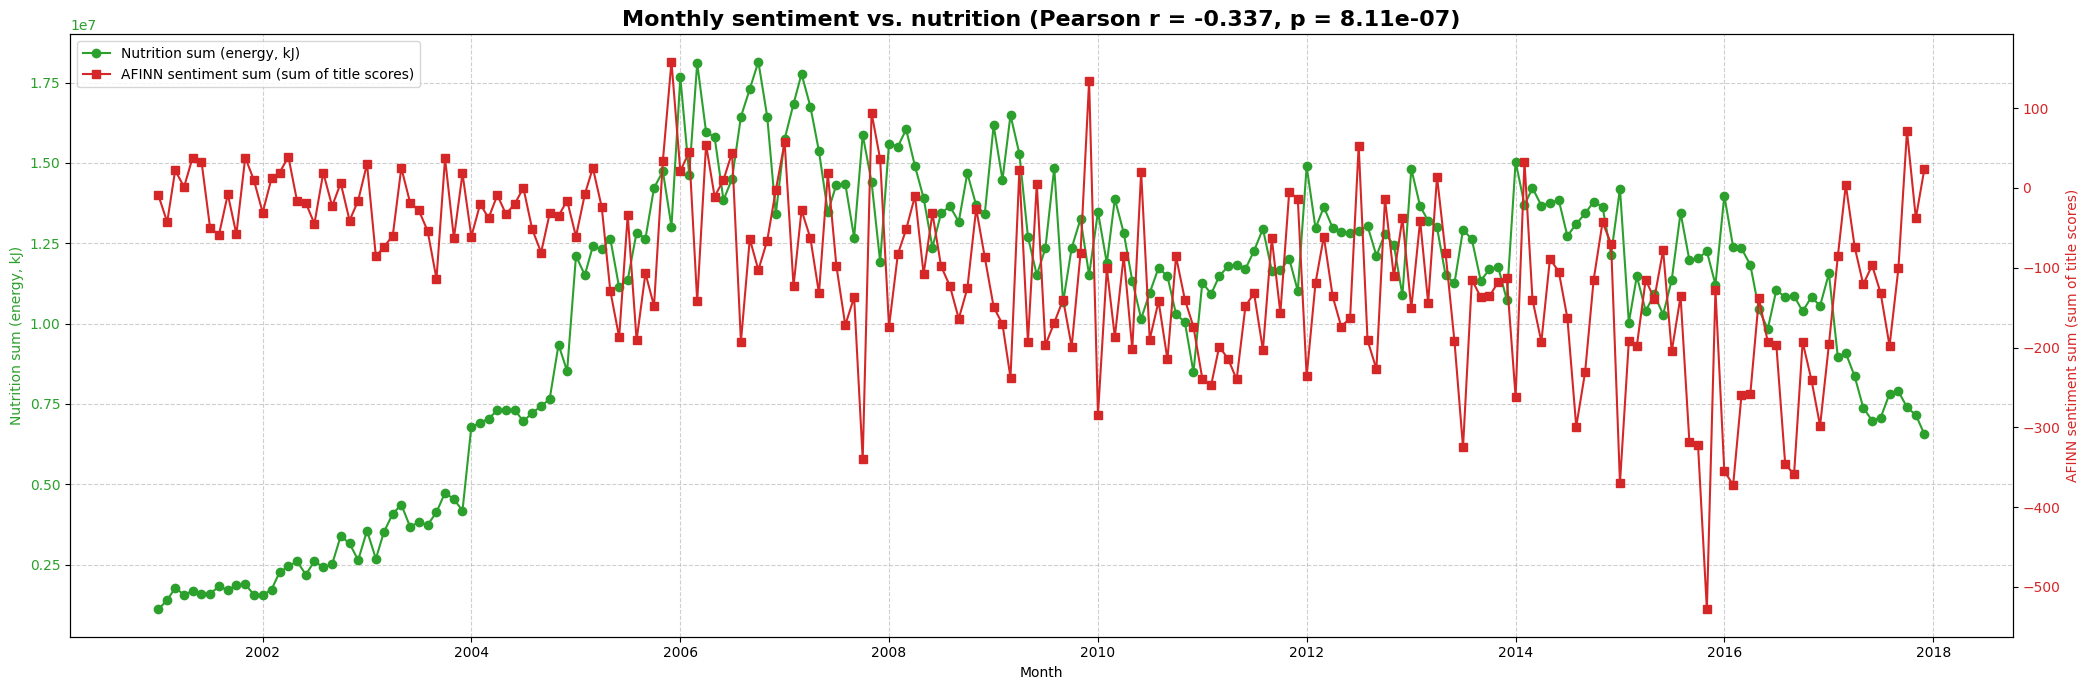

In [19]:
print(comparison)
print(pearson_with_nutrition(comparison, "sentiment_sum").to_string(index=False))
plot_vs_nutrition(comparison, "sentiment_sum", "sentiment", "AFINN sentiment sum (sum of title scores)")

      sentiment_sum  n_titles  nutrition_sum
2001          -85.0     12555   1.952680e+07
2002          -96.0     18734   2.946961e+07
2003         -388.0     30493   4.699087e+07
2004         -397.0     58013   8.978882e+07
2005         -672.0     95236   1.509350e+08
2006         -408.0    122252   1.922832e+08
2007         -888.0    116219   1.795255e+08
2008        -1083.0    110206   1.703669e+08
2009        -1377.0     98532   1.616222e+08
2010        -1786.0     78866   1.365537e+08
2011        -1861.0     71813   1.405467e+08
2012        -1417.0     76610   1.543210e+08
2013        -1540.0     73454   1.484966e+08
2014        -1677.0     81174   1.630746e+08
2015        -2730.0     73789   1.395533e+08
2016        -3210.0     70231   1.352908e+08
2017         -944.0     49005   9.621811e+07
       series     nutrition  pearson_r  p_value  n_periods
sentiment_sum nutrition_sum  -0.450882   0.0693         17


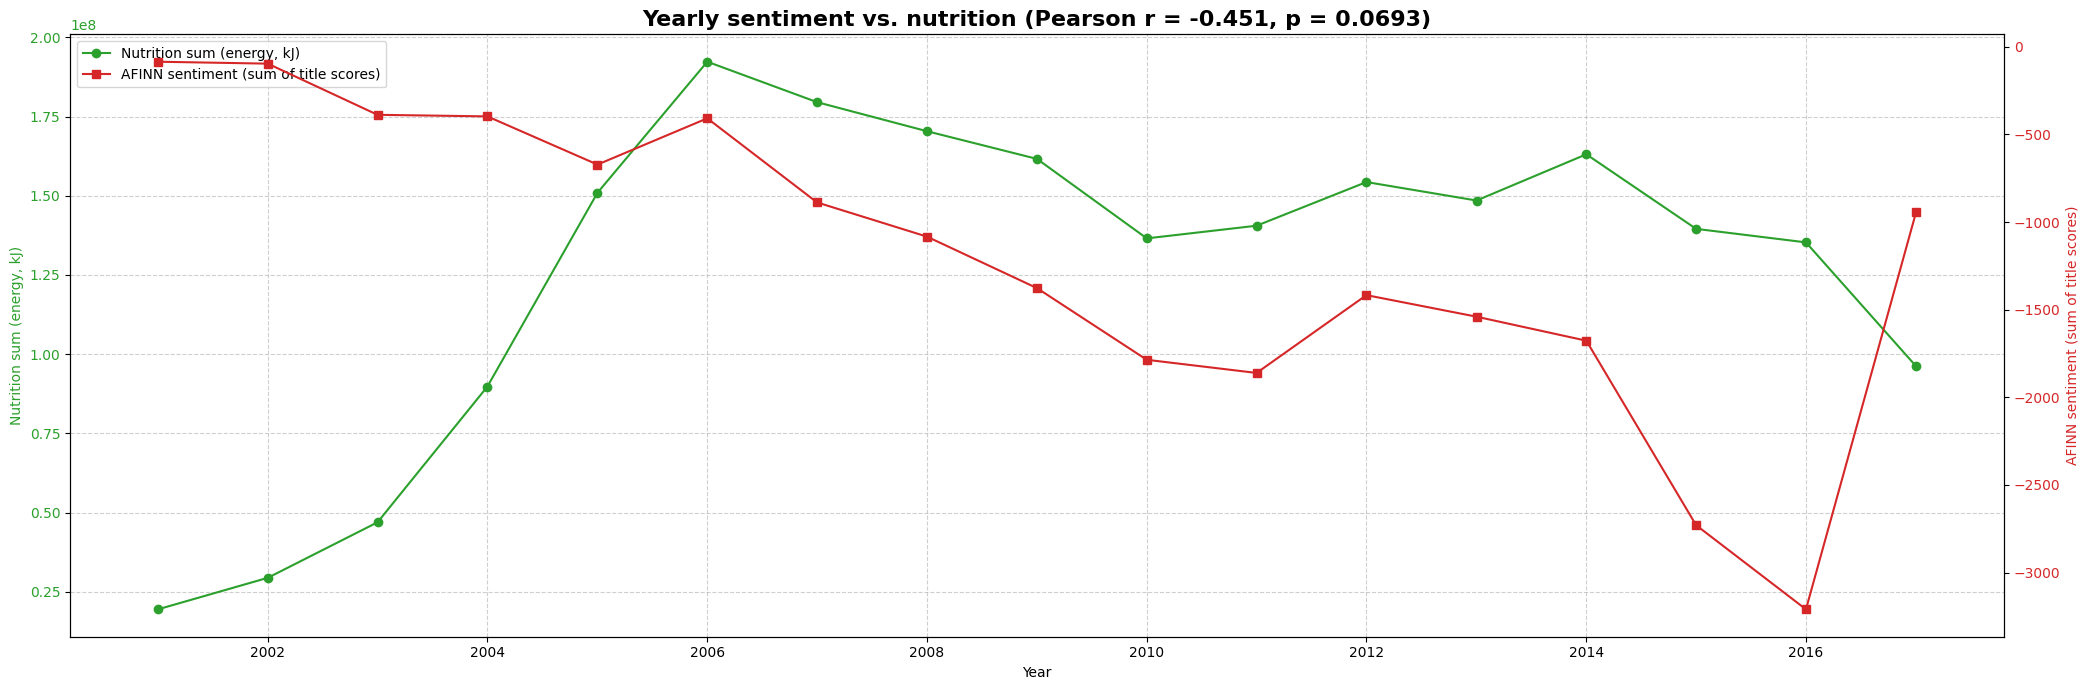

In [20]:
# part 3)
yearly_sentiment = monthly_sentiment.groupby(monthly_sentiment.index.str[:4]).sum()
yearly_nutrition = monthly_nutrition_df.groupby(monthly_nutrition_df.index.str[:4]).sum()

yearly_comparison = build_comparison(yearly_nutrition, yearly_sentiment)
print(yearly_comparison)
print(pearson_with_nutrition(yearly_comparison, "sentiment_sum").to_string(index=False))
plot_vs_nutrition(yearly_comparison, "sentiment_sum", "sentiment", "AFINN sentiment (sum of title scores)",
                  period_label="Yearly", x_label="Year")

In [21]:
# part 4)
def diversity_from_counts(counts_df):
    return (counts_df > 0).sum(axis=1).to_frame("n_distinct_foods")

monthly_diversity = diversity_from_counts(counts)

# Produces single dataframe with no duplicate foods for years
# 2001_1 {"kala": 2, "kani": 1}, 2001_2 {"ankka": 1, "kani": 3}, ...
# -> 2001 {"ankka": 1, "kala": 2, "kani": 4}
yearly_counts = counts.groupby(counts.index.str[:4]).sum()

# counts distinct foods
yearly_diversity = diversity_from_counts(yearly_counts)

         n_distinct_foods  nutrition_sum
month                                   
2001-01               138   1.106156e+06
2001-02               136   1.393052e+06
2001-03               164   1.774585e+06
2001-04               136   1.560076e+06
2001-05               141   1.673610e+06
...                   ...            ...
2017-08               307   7.815354e+06
2017-09               297   7.890702e+06
2017-10               282   7.398551e+06
2017-11               287   7.155081e+06
2017-12               279   6.554614e+06

[204 rows x 2 columns]
          series     nutrition  pearson_r      p_value  n_periods
n_distinct_foods nutrition_sum   0.939455 6.620091e-96        204


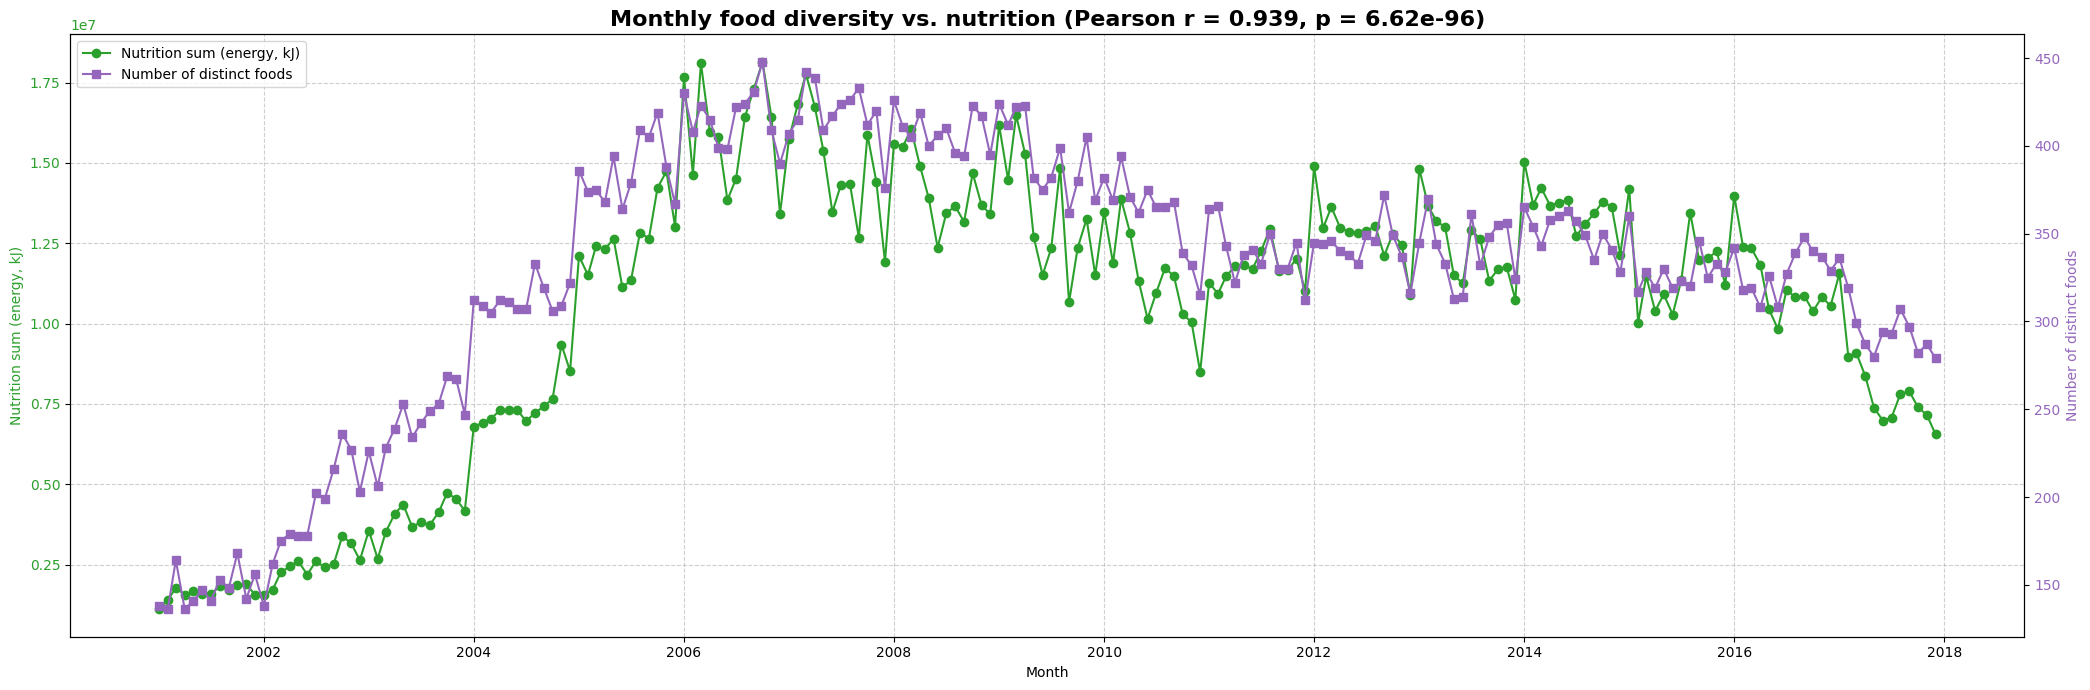

In [22]:
# Monthly
monthly_diversity_comparison = build_comparison(monthly_nutrition_df, monthly_diversity)
print(monthly_diversity_comparison)
print(pearson_with_nutrition(monthly_diversity_comparison, "n_distinct_foods").to_string(index=False))
plot_vs_nutrition(monthly_diversity_comparison, "n_distinct_foods", "food diversity", "Number of distinct foods",
                  other_color="tab:purple")

       n_distinct_foods  nutrition_sum
month                                 
2001                340   1.952680e+07
2002                434   2.946961e+07
2003                490   4.699087e+07
2004                572   8.978882e+07
2005                661   1.509350e+08
2006                674   1.922832e+08
2007                691   1.795255e+08
2008                673   1.703669e+08
2009                672   1.616222e+08
2010                619   1.365537e+08
2011                615   1.405467e+08
2012                614   1.543210e+08
2013                623   1.484966e+08
2014                618   1.630746e+08
2015                600   1.395533e+08
2016                593   1.352908e+08
2017                555   9.621811e+07
          series     nutrition  pearson_r      p_value  n_periods
n_distinct_foods nutrition_sum   0.953005 3.512781e-09         17


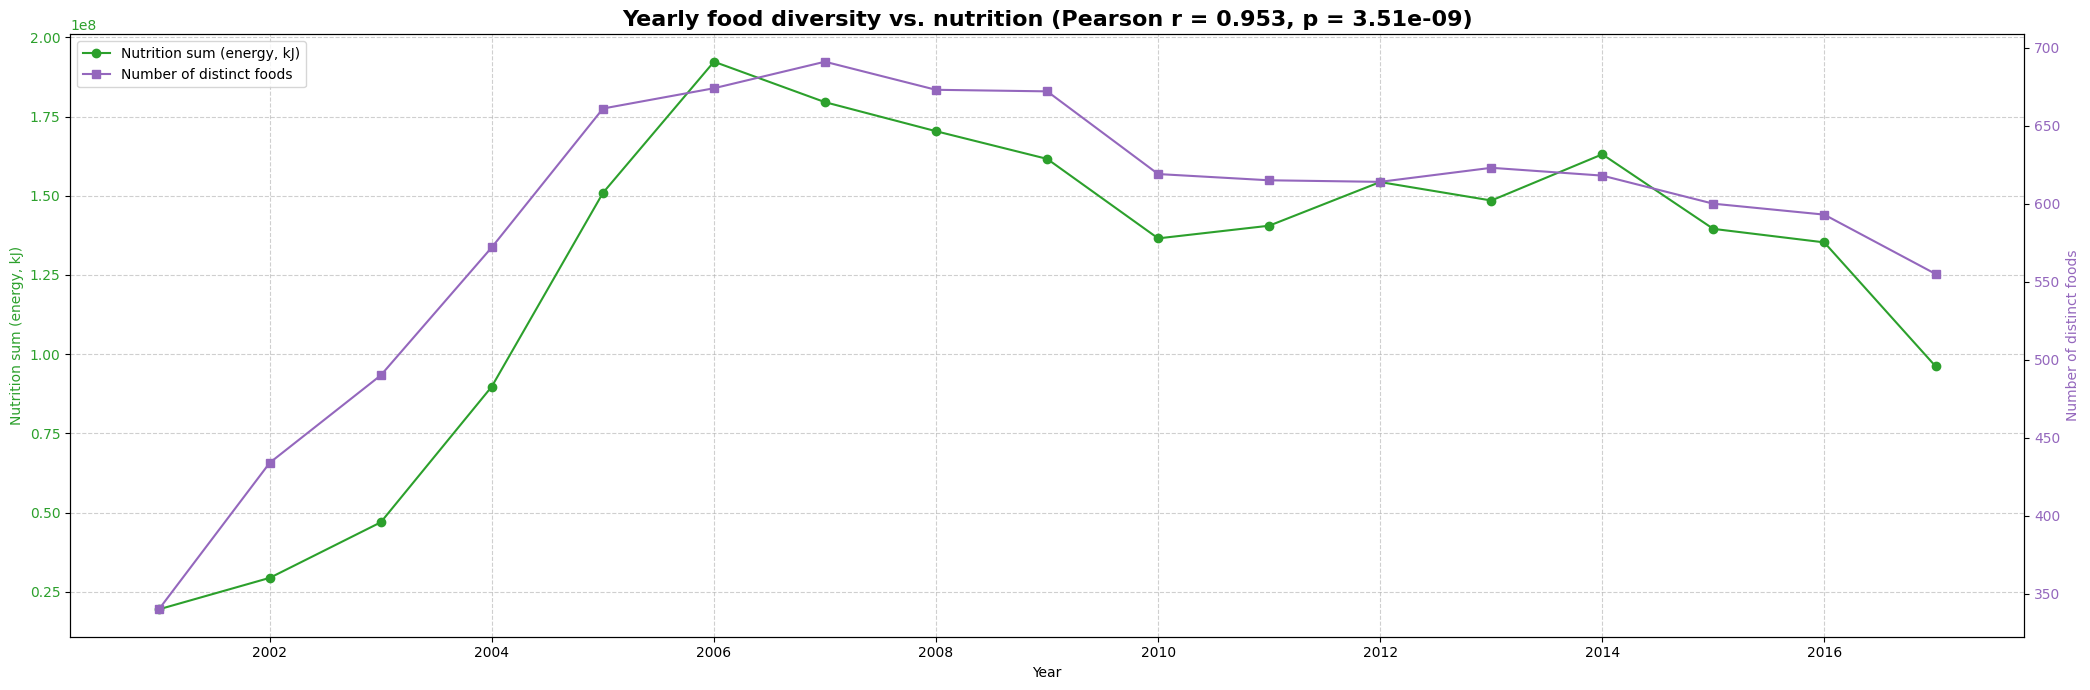

In [23]:
# Yearly
yearly_diversity_comparison = build_comparison(yearly_nutrition, yearly_diversity)
print(yearly_diversity_comparison)
print(pearson_with_nutrition(yearly_diversity_comparison, "n_distinct_foods").to_string(index=False))
plot_vs_nutrition(yearly_diversity_comparison, "n_distinct_foods", "food diversity", "Number of distinct foods",
                  other_color="tab:purple", period_label="Yearly", x_label="Year")

               series     nutrition  pearson_r      p_value  n_periods
n_distinct_categories nutrition_sum   0.561842 2.273333e-18        204


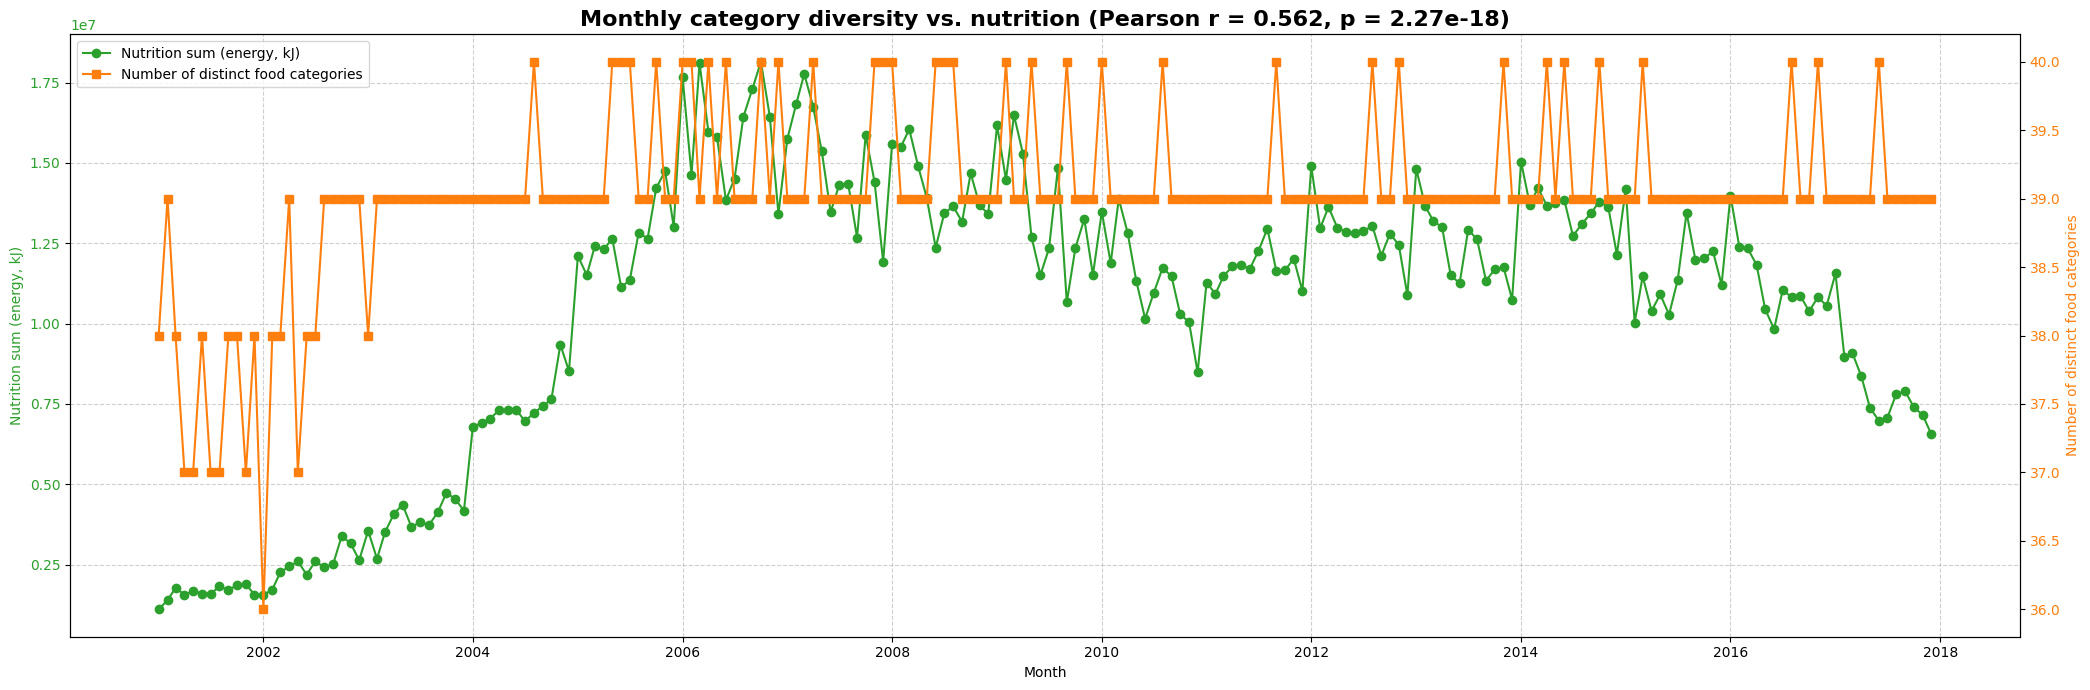

               series     nutrition  pearson_r  p_value  n_periods
n_distinct_categories nutrition_sum   0.867218 0.000007         17


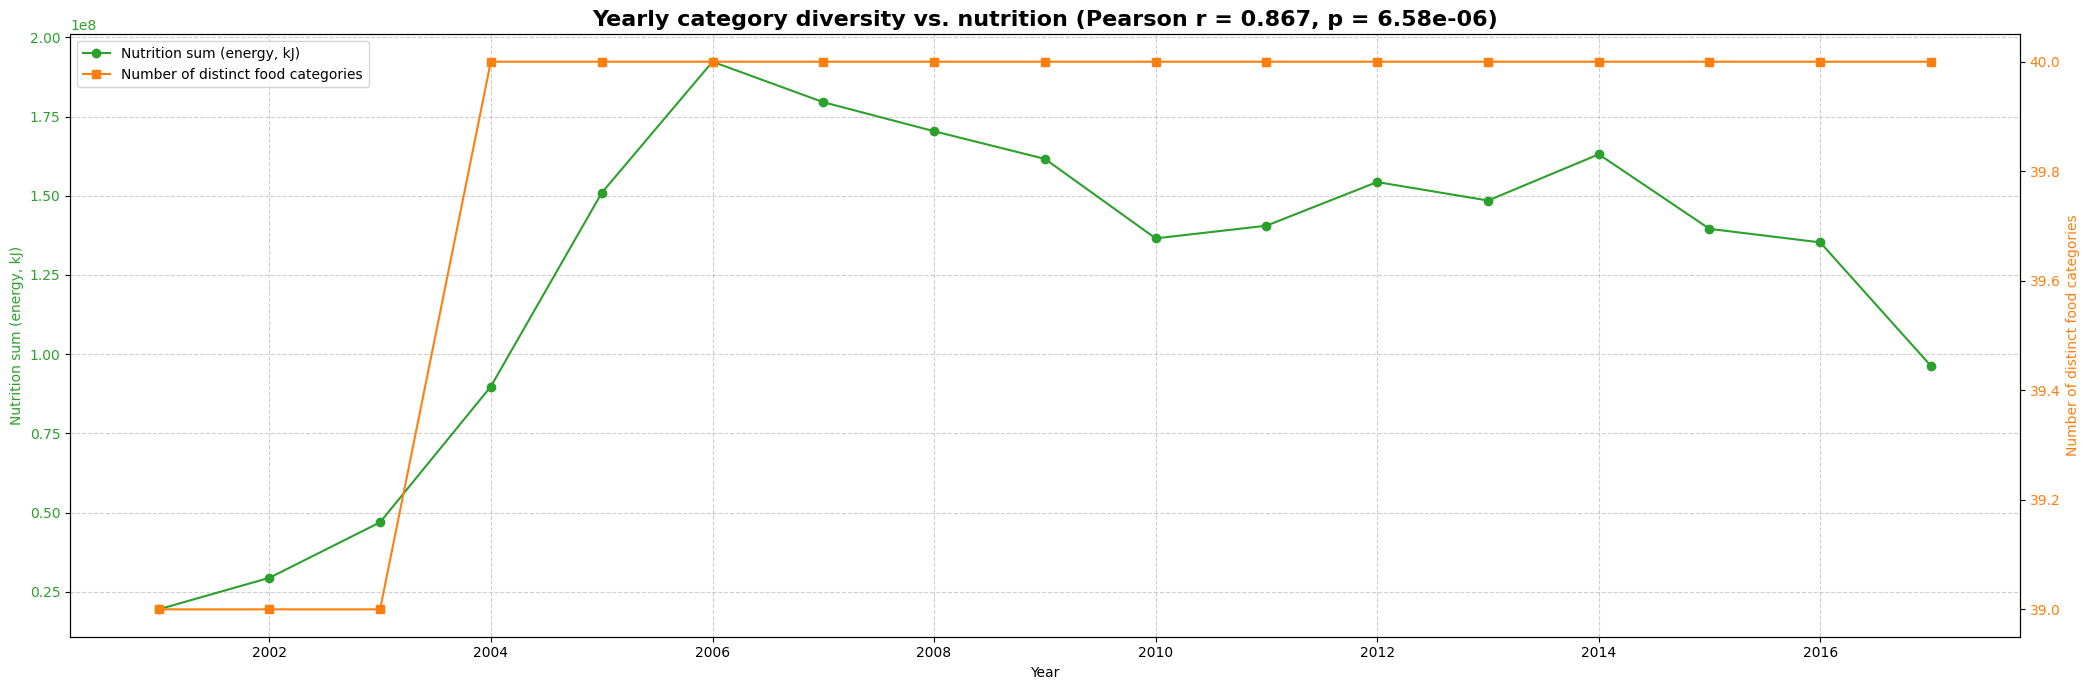

In [24]:
# Task 5
Fineli_with_category = Path("datasets/fineli_categories_40.xlsx")

food_categories = pd.read_excel(Fineli_with_category, index_col=0)["kategoria"]
food_categories = food_categories[~food_categories.index.duplicated(keep="first")]

cat_of_food = food_categories.reindex(counts.columns).values
counts_by_category = counts.T.groupby(cat_of_food).sum().T
yearly_counts_by_category = counts_by_category.groupby(counts_by_category.index.str[:4]).sum()

def category_diversity(cat_counts):
    """number of distinct categories mentioned in the period"""
    return (cat_counts > 0).sum(axis=1).to_frame("n_distinct_categories")

monthly_cat_div = category_diversity(counts_by_category)
yearly_cat_div  = category_diversity(yearly_counts_by_category)

# by month
for col, label in [("n_distinct_categories", "Number of distinct food categories")]:
    comp = build_comparison(monthly_nutrition_df, monthly_cat_div[[col]])
    print(pearson_with_nutrition(comp, col).to_string(index=False))
    plot_vs_nutrition(comp, col, "category diversity", label, other_color="tab:orange")

# by year
for col, label in [("n_distinct_categories", "Number of distinct food categories")]:
    comp = build_comparison(yearly_nutrition, yearly_cat_div[[col]])
    print(pearson_with_nutrition(comp, col).to_string(index=False))
    plot_vs_nutrition(comp, col, "category diversity", label, other_color="tab:orange",
                      period_label="Yearly", x_label="Year")


In [25]:
# Part 6)
def calculate_vocabulary_growth(titles_df):
    df = titles_df[["month", "title"]].dropna().copy()

    df["tokens"] = df["title"].map(word_tokenize)
    df["n_tokens"] = df["tokens"].str.len()

    # Aggregate token counts and token lists per month
    monthly = (
        df.groupby("month")
        .agg(
            total_tokens=("n_tokens", "sum"),
            tokens=("tokens", lambda s: [
                lemmatize_word(token.lower()) for title_tokens in s for token in title_tokens
            ])
        )
        .sort_index()
    )

    # Cumulative token count and vocabulary size
    monthly["total_tokens"] = monthly["total_tokens"].cumsum()

    monthly["vocabulary_size"] = (
        monthly["tokens"]
        .map(set)
        .map(lambda _: 0)
    )

    vocabulary = set()
    vocabulary_sizes = []

    for tokens in monthly["tokens"]:
        vocabulary.update(tokens)
        vocabulary_sizes.append(len(vocabulary))

    monthly["vocabulary_size"] = vocabulary_sizes

    return monthly.drop(columns="tokens").reset_index()


vocabulary_df = calculate_vocabulary_growth(titles_df)

display(vocabulary_df)

,month,total_tokens,vocabulary_size
0,2001-01,2971,1277
1,2001-02,6795,2516
2,2001-03,10847,3660
3,2001-04,14395,4536
4,2001-05,18180,5429
...,...,...,...
199,2017-08,4387480,379332
200,2017-09,4403961,380432
201,2017-10,4420098,381525
202,2017-11,4435360,382555


In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [27]:
# Remove invalid observations before taking logarithms
fit_df = vocabulary_df[
    (vocabulary_df["total_tokens"] > 0)
    & (vocabulary_df["vocabulary_size"] > 0)
].copy()

X = np.log(fit_df[["total_tokens"]].to_numpy())
y = np.log(fit_df["vocabulary_size"].to_numpy())

model = LinearRegression()
model.fit(X, y)

log_K = model.intercept_
K = np.exp(log_K)
beta = model.coef_[0]

y_pred = model.predict(X)

r_squared = r2_score(y, y_pred)

n = len(y)
p = 1

adjusted_r_squared = (
    1-(1-r_squared) * (n-1) / (n-p-1)
)

print(f"Heap's law: V(N) = {K:.4f} * N^{beta:.4f}")
print(f"K: {K:.4f}")
print(f"Beta: {beta:.4f}")
print(f"R-squared (log space): {r_squared:.4f}")
print(f"Adjusted R-squared (log space): {adjusted_r_squared:.4f}")

Heap's law: V(N) = 2.6583 * N^0.7761
K: 2.6583
Beta: 0.7761
R-squared (log space): 1.0000
Adjusted R-squared (log space): 1.0000


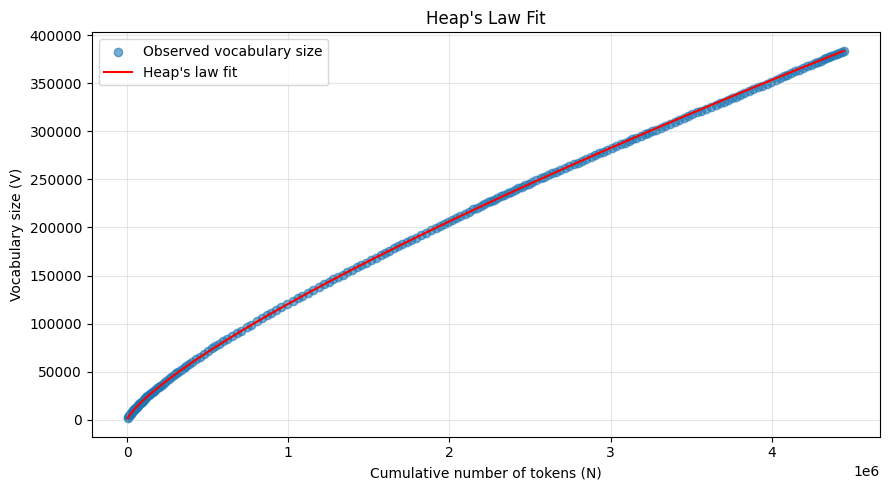

In [28]:
N = fit_df["total_tokens"].to_numpy()
V = fit_df["vocabulary_size"].to_numpy()

# Fitted values in the original scale
V_pred = K * N**beta

plt.figure(figsize=(9, 5))

plt.scatter(N, V, label="Observed vocabulary size", alpha=0.6)
plt.plot(N, V_pred, label="Heap's law fit", color="red")

plt.xlabel("Cumulative number of tokens (N)")
plt.ylabel("Vocabulary size (V)")
plt.title("Heap's Law Fit")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# Part 7)
df = titles_df.loc[titles_df["title"].notna(), ["title"]].copy()
df["title_length"] = df["title"].str.len()

# 20-bin subdivision
df["length_bin"] = pd.cut(df["title_length"], bins=20)

bin_frequencies = (
    df.groupby("length_bin", observed=False)
    .size()
    .reset_index(name="frequency")
)

In [34]:
ranked = (
    bin_frequencies
    .sort_values("frequency", ascending=False)
    .reset_index(drop=True)
)

ranked["rank"] = np.arange(1, len(ranked) + 1)

fit_df = ranked[ranked["frequency"] > 0].copy()

# Fit log(frequency) = log(C) - s * log(rank)
X = np.log(fit_df[["rank"]].to_numpy())
y = np.log(fit_df["frequency"].to_numpy())

model = LinearRegression()
model.fit(X, y)

C = np.exp(model.intercept_)
s = -model.coef_[0]

y_pred = model.predict(X)

r_squared = r2_score(y, y_pred)

n = len(y)
p = 1

adjusted_r_squared = (
    1 - (1 - r_squared) * (n - 1) / (n - p - 1)
    if n > p + 1 else np.nan
)

print(f"Zipf's law: f(r) = {C:.4f} * r^(-{s:.4f})")
print(f"Exponent (s): {s:.4f}")
print(f"R-squared: {r_squared:.4f}")
print(f"Adjusted R-squared: {adjusted_r_squared:.4f}")

display(ranked[["rank", "length_bin", "frequency"]])

Zipf's law: f(r) = 23898246.3119 * r^(-4.4847)
Exponent (s): 4.4847
R-squared: 0.7326
Adjusted R-squared: 0.7178


,rank,length_bin,frequency
0,1,"(12.8, 19.2]",311266
1,2,"(19.2, 25.6]",246574
2,3,"(25.6, 32.0]",207176
3,4,"(6.4, 12.8]",172169
4,5,"(32.0, 38.4]",110232
5,6,"(38.4, 44.8]",68357
6,7,"(44.8, 51.2]",53536
7,8,"(-0.128, 6.4]",40917
8,9,"(51.2, 57.6]",12840
9,10,"(57.6, 64.0]",12292


In [ ]:
fitted_frequency = C * fit_df["rank"].to_numpy() ** (-s)

plt.figure(figsize=(9, 5))

plt.scatter(
    fit_df["rank"],
    fit_df["frequency"],
    label="Observed bin frequencies",
    alpha=0.4
)

plt.plot(
    fit_df["rank"],
    fitted_frequency,
    color="red",
    label="Zipf's law fit"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Bin rank (log scale)")
plt.ylabel("Frequency (log scale)")
plt.title("Zipf's Law: Thread Title Length Frequencies")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()